# Segbench

In [ ]:
import gc
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from huggingface_hub import list_models
from PIL import Image
from tqdm.auto import tqdm
from transformers import (
    AutoModelForSemanticSegmentation,
    AutoModelForUniversalSegmentation,
)

from utils.utils import sync

device = "cuda" if torch.cuda.is_available() else "cpu"

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

In [10]:
# Gather the dataset.
root = Path("data_semantics/training")
images = sorted((root / "image_2").glob("*.png"))
dataset = [(img, root / "semantic_rgb" / img.name) for img in images]

print(f"{len(dataset)=}")

len(dataset)=200


In [11]:
dataset[0]

(PosixPath('data_semantics/training/image_2/000000_10.png'),
 PosixPath('data_semantics/training/semantic_rgb/000000_10.png'))

In [12]:
img_path, sem_path = dataset[0]

In [13]:
img = Image.open(img_path).convert("RGB")
sem = Image.open(sem_path).convert("RGB")

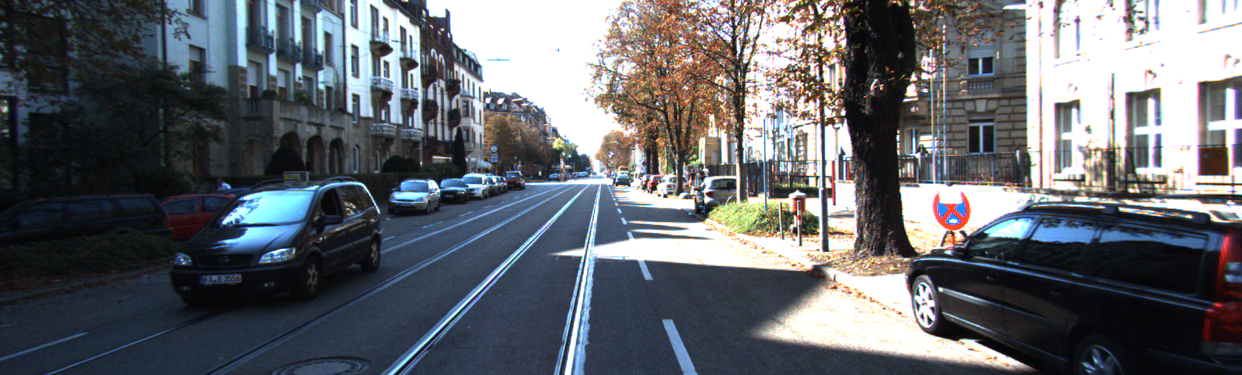

In [14]:
img

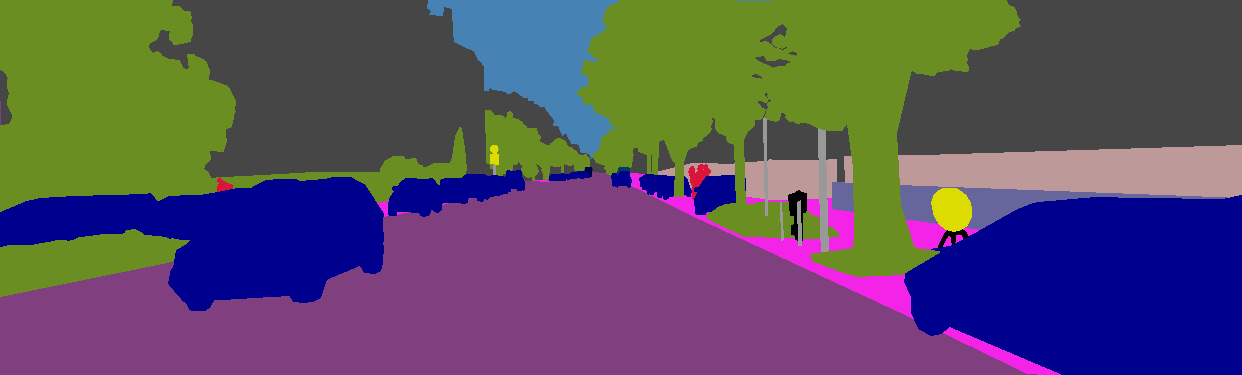

In [15]:
sem

## Evaluate segmentation models

Output class definitions for [cityscape](https://www.cityscapes-dataset.com/dataset-overview/?utm_source=chatgpt.com#class-definitions) and the corresponding [colors](https://github.com/mcordts/cityscapesScripts/blob/master/cityscapesscripts/helpers/labels.py).

In [16]:
CAR_RGB = (0, 0, 142)  # Cityscapes color for "car".

In [17]:
models = {
    m.id: AutoModelForSemanticSegmentation
    for m in sorted(list_models(author="nvidia", search="segformer"), key=lambda m: m.id)
    if "cityscapes" in m.id
}
models |= {
    f"facebook/mask2former-swin-{size}-cityscapes-semantic": AutoModelForUniversalSegmentation
    for size in ["tiny", "small", "base-IN21k"]
}
models

{'nvidia/segformer-b0-finetuned-cityscapes-1024-1024': transformers.models.auto.modeling_auto.AutoModelForSemanticSegmentation,
 'nvidia/segformer-b0-finetuned-cityscapes-512-1024': transformers.models.auto.modeling_auto.AutoModelForSemanticSegmentation,
 'nvidia/segformer-b0-finetuned-cityscapes-640-1280': transformers.models.auto.modeling_auto.AutoModelForSemanticSegmentation,
 'nvidia/segformer-b0-finetuned-cityscapes-768-768': transformers.models.auto.modeling_auto.AutoModelForSemanticSegmentation,
 'nvidia/segformer-b1-finetuned-cityscapes-1024-1024': transformers.models.auto.modeling_auto.AutoModelForSemanticSegmentation,
 'nvidia/segformer-b2-finetuned-cityscapes-1024-1024': transformers.models.auto.modeling_auto.AutoModelForSemanticSegmentation,
 'nvidia/segformer-b3-finetuned-cityscapes-1024-1024': transformers.models.auto.modeling_auto.AutoModelForSemanticSegmentation,
 'nvidia/segformer-b4-finetuned-cityscapes-1024-1024': transformers.models.auto.modeling_auto.AutoModelForSe

## Metrics

We score each model on the **car** class only. Every pixel lands in one of four cases:

- **TP** (true positive): car in the ground truth, predicted as car
- **FN** (false negative): car in the ground truth, but missed
- **FP** (false positive): not a car, but predicted as car
- **TN** (true negative): not a car, and not predicted as car

<img src="figures/iou_recall.svg" style="display: block; margin: 24px auto; width: 1000px;">

**Recall** asks: *of all true car pixels, how many did the model find?*
Recall ignores FP, so a model that labels the whole image "car" scores a perfect 1.0. It tells us whether cars are missed, not whether the masks are clean.

**IoU** (intersection over union) closes that loophole by also penalizing FP:
IoU only reaches 1.0 when the predicted mask matches the ground truth exactly. Missed pixels (FN) and hallucinated pixels (FP) both shrink it.

TP, FP and FN are summed over all 200 images *before* dividing, so large, nearby cars contribute more pixels than small, distant ones.

In [18]:
def evaluate(name, model_cls):
    model = model_cls.from_pretrained(name).to(device).eval()
    processor = AutoImageProcessor.from_pretrained(name)
    car = model.config.label2id["car"]

    inter = union = gt_total = 0
    times = []
    for img_path, sem_path in dataset:
        img = Image.open(img_path).convert("RGB")
        gt = (np.array(Image.open(sem_path).convert("RGB")) == CAR_RGB).all(-1)
        inputs = processor(images=img, return_tensors="pt").to(device)

        # Run the model and time it.
        sync(device)
        start = time.perf_counter()
        with torch.no_grad():
            outputs = model(**inputs)
        sync(device)
        times.append(time.perf_counter() - start)

        pred = processor.post_process_semantic_segmentation(outputs, target_sizes=[img.size[::-1]])[0].cpu().numpy() == car
        inter += (pred & gt).sum()
        union += (pred | gt).sum()
        gt_total += gt.sum()
    
    # Clean up.
    del model, inputs, outputs
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

    return {
        "model": name.split("/")[-1],
        "car_iou": inter / union,
        "car_recall": inter / gt_total,
        "ms_per_img": 1000 * np.median(times[10:]),  # Skip 10 warm-up images, median resists outliers.
    }

In [19]:
results = [evaluate(name, cls) for name, cls in tqdm(models.items(), total=len(models))]

  0%|          | 0/12 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

...

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-cityscapes-semantic
Key                                                                                                                                | Status     | 
-----------------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                               | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params 

Loading weights:   0%|          | 0/758 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-small-cityscapes-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the c

Loading weights:   0%|          | 0/329 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-base-IN21k-cityscapes-semantic
Key                                                                                                                                             | Status     | 
------------------------------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.model.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.intermediate.dense.weight                                    | UNEXPECTED | 
model.pixel_level_module.encoder.model.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.layernorm_after.weight                                       | UNEXPECTED | 
model.pixel_level_module.encoder.model.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.key.weight                                    | UNEXPECTED | 
model.pixel_level_module.encoder.model.encoder.layers.{0, 1, 2, 3}.blocks.

In [20]:
results

[{'model': 'segformer-b0-finetuned-cityscapes-1024-1024',
  'car_iou': np.float64(0.8035143159438255),
  'car_recall': np.float64(0.9015826081953413),
  'ms_per_img': np.float64(14.247898999997233)},
 {'model': 'segformer-b0-finetuned-cityscapes-512-1024',
  'car_iou': np.float64(0.8046788604099266),
  'car_recall': np.float64(0.9076511997364076),
  'ms_per_img': np.float64(14.502705500035518)},
 {'model': 'segformer-b0-finetuned-cityscapes-640-1280',
  'car_iou': np.float64(0.8008749341956597),
  'car_recall': np.float64(0.9163487459441321),
  'ms_per_img': np.float64(14.685066499964705)},
 {'model': 'segformer-b0-finetuned-cityscapes-768-768',
  'car_iou': np.float64(0.8069338339900446),
  'car_recall': np.float64(0.9117428488162557),
  'ms_per_img': np.float64(14.637603499977558)},
 {'model': 'segformer-b1-finetuned-cityscapes-1024-1024',
  'car_iou': np.float64(0.8605389721107858),
  'car_recall': np.float64(0.9252515982697108),
  'ms_per_img': np.float64(147.31132249994516)},
 {'m

In [21]:
torch.save(results, RESULTS_DIR / "results.pt")

In [22]:
results = torch.load(RESULTS_DIR / "results.pt", weights_only=False)

## Plot results

Skipping mask2former-swin-base-IN21k-cityscapes-semantic: car IoU 0.008, likely a loading or label bug.


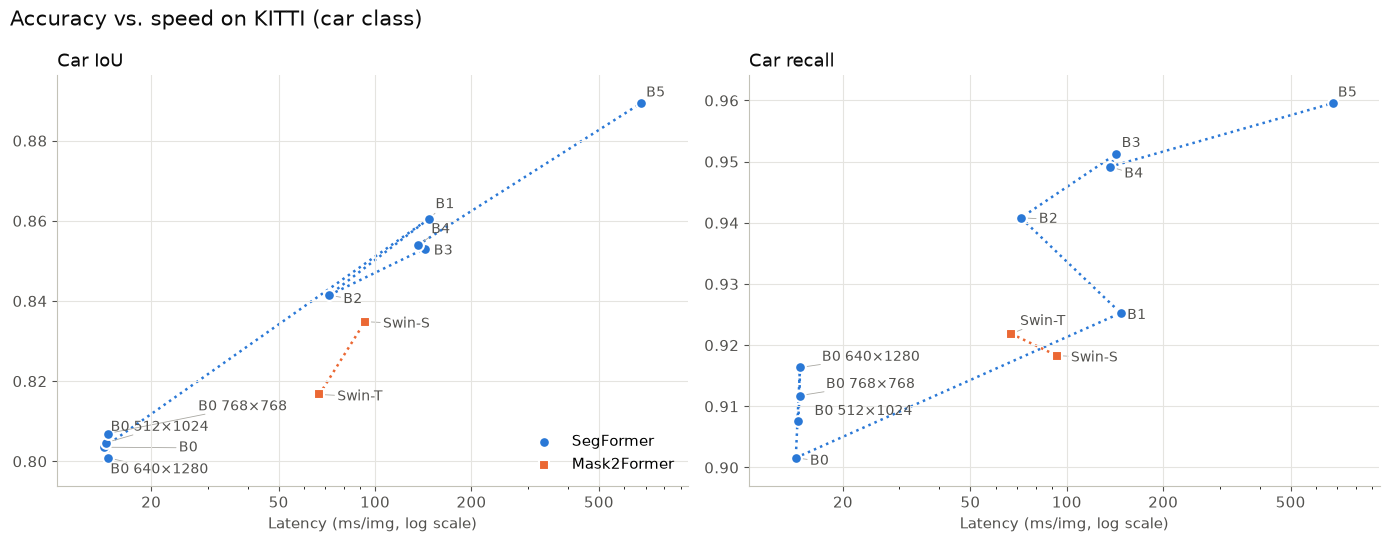

In [23]:
import numpy as np
import pandas as pd
from adjustText import adjust_text

FAMILIES = {  # Name fragment -> (legend name, color, marker).
    "segformer": ("SegFormer", "#2a78d6", "o"),
    "mask2former": ("Mask2Former", "#eb6834", "s"),
    "eomt": ("EoMT", "#1baf7a", "D"),
    "oneformer": ("OneFormer", "#eda100", "^"),
}

seg = "segformer-{}-finetuned-cityscapes-{}"
LINES = {  # Models connected by a dotted line, in order.
    "segformer": [seg.format(f"b{i}", "1024-1024") for i in range(6)],
    "segformer-b0": [seg.format("b0", r) for r in ["512-1024", "768-768", "640-1280", "1024-1024"]],
    "mask2former": [f"mask2former-swin-{s}-cityscapes-semantic" for s in ["tiny", "small", "base-IN21k", "large"]],
}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4e0"


def family(model):
    return next(key for key in FAMILIES if key in model)


def label(model):
    if model.startswith("segformer"):
        size = model.split("-")[1].upper()
        res = model.split("cityscapes-")[1].replace("-", "×")
        return size if res == "1024×1024" else f"{size} {res}"
    if model.startswith("mask2former"):
        return "Swin-" + model.split("-")[2][0].upper()  # tiny -> Swin-T, base-IN21k -> Swin-B, ...
    return FAMILIES[family(model)][0] + "-L"


df = pd.DataFrame(results).set_index("model")
broken = df["car_iou"] < 0.5  # Far below every working model: a failed run, not a real result.
for model, row in df[broken].iterrows():
    print(f"Skipping {model}: car IoU {row['car_iou']:.3f}, likely a loading or label bug.")
df = df[~broken]

plt.rcParams.update({"font.size": 11, "axes.titlesize": 13})
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)

for ax, metric, title in [(axes[0], "car_iou", "Car IoU"), (axes[1], "car_recall", "Car recall")]:
    avoid_x, avoid_y = list(df["ms_per_img"]), list(df[metric])  # Labels steer clear of these points.
    for key, names in LINES.items():
        line = df.reindex(names).dropna()
        ax.plot(line["ms_per_img"], line[metric], ":", lw=1.8, color=FAMILIES[key.split("-")[0]][1], zorder=1)
        for (x0, y0), (x1, y1) in zip(line[["ms_per_img", metric]].values[:-1], line[["ms_per_img", metric]].values[1:]):
            t = np.linspace(0, 1, 25)
            avoid_x += list(x0 * (x1 / x0) ** t)  # Sample along the segment in log-x.
            avoid_y += list(y0 + (y1 - y0) * t)

    for key, (name, color, marker) in FAMILIES.items():
        pts = df[df.index.map(family) == key]
        if len(pts):
            ax.scatter(pts["ms_per_img"], pts[metric], s=80 if marker == "^" else 60, color=color,
                       marker=marker, edgecolor="white", linewidth=1.5, label=name, zorder=3)

    texts = [ax.text(row["ms_per_img"], row[metric], label(model), fontsize=10, color=MUTED, zorder=4)
             for model, row in df.iterrows()]

    ax.set_xscale("log")
    lo, hi = df["ms_per_img"].min() / 1.4, df["ms_per_img"].max() * 1.4
    ax.set_xlim(lo, hi)
    ticks = [t for t in [5, 10, 20, 50, 100, 200, 500, 1000, 2000] if lo <= t <= hi]
    ax.set_xticks(ticks, [str(t) for t in ticks])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    pad = 0.08 * (df[metric].max() - df[metric].min())
    ax.set_ylim(df[metric].min() - pad, df[metric].max() + pad)

    ax.set_title(title, loc="left", color=INK)
    ax.set_xlabel("Latency (ms/img, log scale)", color=MUTED)
    ax.grid(True, which="major", color=GRID, lw=0.8)
    ax.tick_params(colors=MUTED)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#c3c2b7")

    adjust_text(texts, x=avoid_x, y=avoid_y, ax=ax, expand=(1.25, 1.5),
                target_x=df["ms_per_img"].values, target_y=df[metric].values,
                arrowprops=dict(arrowstyle="-", color="#a9a8a2", lw=0.6))

axes[0].legend(frameon=False, loc="lower right")
fig.suptitle("Accuracy vs. speed on KITTI (car class)", x=0.01, ha="left", fontsize=15, color=INK)
fig.tight_layout()
plt.show()
fig.savefig("figures/accuracy_vs_speed.png", dpi=600, bbox_inches="tight")  # Raster, ~8000 px wide.

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/930 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/758 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/329 [00:00<?, ?it/s]

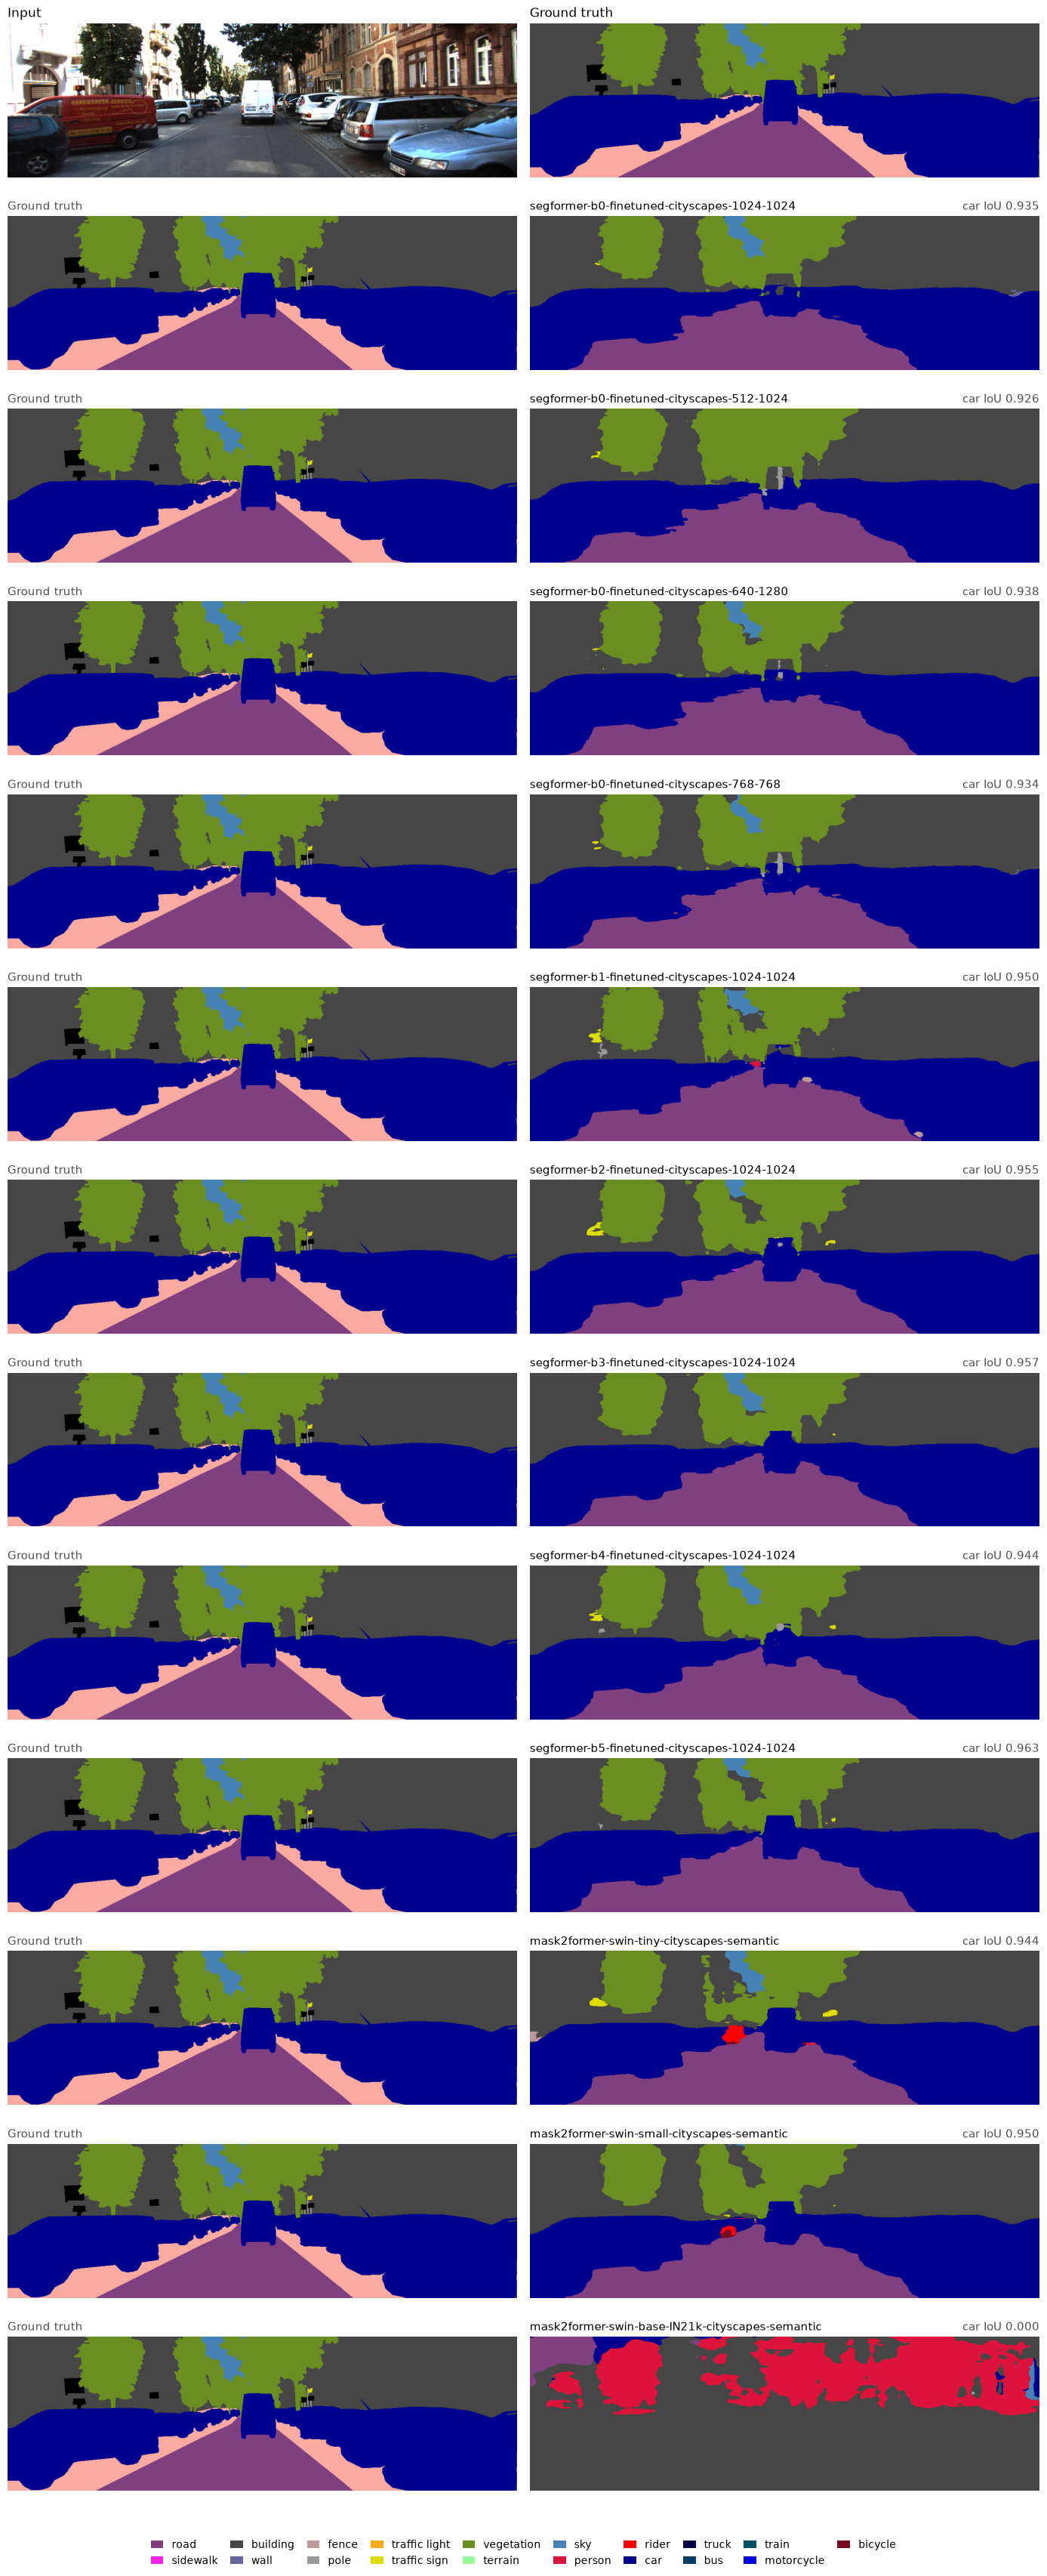

In [24]:
# Compare ground truth with each model's prediction on one KITTI image.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Patch
from PIL import Image
from transformers import AutoImageProcessor, AutoProcessor
from transformers.utils import logging

logging.set_verbosity_error()  # Hide weight-loading reports.
assert "models" in globals(), "Run the cell that defines `models` first."

IDX = 5  # Which training image to show.
device = "cuda" if torch.cuda.is_available() else "cpu"

# Cityscapes classes and colors, indexed by train ID.
CLASSES = [
    "road", "sidewalk", "building", "wall", "fence", "pole", "traffic light", "traffic sign",
    "vegetation", "terrain", "sky", "person", "rider", "car", "truck", "bus", "train",
    "motorcycle", "bicycle",
]
PALETTE = np.array([
    (128, 64, 128), (244, 35, 232), (70, 70, 70), (102, 102, 156), (190, 153, 153),
    (153, 153, 153), (250, 170, 30), (220, 220, 0), (107, 142, 35), (152, 251, 152),
    (70, 130, 180), (220, 20, 60), (255, 0, 0), (0, 0, 142), (0, 0, 70),
    (0, 60, 100), (0, 80, 100), (0, 0, 230), (119, 11, 32),
], dtype=np.uint8)
CAR_RGB = tuple(PALETTE[CLASSES.index("car")])

# Load the image and its ground truth.
root = Path("data_semantics/training")
img_path = sorted((root / "image_2").glob("*.png"))[IDX]
img = Image.open(img_path).convert("RGB")
gt = Image.open(root / "semantic_rgb" / img_path.name).convert("RGB")
gt_car = (np.array(gt) == CAR_RGB).all(-1)

# Loaded models survive reruns, so changing IDX doesn't reload anything.
_cache = globals().setdefault("_seg_cache", {})


def load(name):
    if name not in _cache:
        proc_cls = AutoProcessor if "oneformer" in name else AutoImageProcessor
        _cache[name] = (proc_cls.from_pretrained(name), models[name].from_pretrained(name).eval())
    return _cache[name]


def predict(name):
    processor, model = load(name)
    extra = {"task_inputs": ["semantic"]} if "oneformer" in name else {}
    inputs = processor(images=img, return_tensors="pt", **extra).to(device)
    model.to(device)
    with torch.no_grad():
        outputs = model(**inputs)
    model.to("cpu")  # Free GPU memory for the next model.
    pred = processor.post_process_semantic_segmentation(
        outputs, target_sizes=[img.size[::-1]]
    )[0].cpu().numpy()
    return pred, model.config.label2id["car"]


# Plot: input and ground truth on top, then one row per model.
names = list(models)
h, w = np.array(img).shape[:2]
row_h = 7 * h / w + 0.45  # Two panels side by side in a 14 in wide figure, plus title space.
fig_h = row_h * (len(names) + 1) + 0.9
fig, axes = plt.subplots(len(names) + 1, 2, figsize=(14, fig_h), squeeze=False)

axes[0, 0].imshow(img)
axes[0, 0].set_title("Input", loc="left", fontsize=12)
axes[0, 1].imshow(gt)
axes[0, 1].set_title("Ground truth", loc="left", fontsize=12)

for (ax_gt, ax_pred), name in zip(axes[1:], names):
    pred, car = predict(name)
    pred_car = pred == car
    iou = (pred_car & gt_car).sum() / max((pred_car | gt_car).sum(), 1)

    ax_gt.imshow(gt)
    ax_gt.set_title("Ground truth", loc="left", fontsize=11, color="#52514e")
    ax_pred.imshow(PALETTE[np.clip(pred, 0, len(PALETTE) - 1)])
    ax_pred.set_title(name.split("/")[-1], loc="left", fontsize=11)
    ax_pred.set_title(f"car IoU {iou:.3f}", loc="right", fontsize=11, color="#52514e")

for ax in axes.flat:
    ax.axis("off")

# Class legend along the bottom.
handles = [Patch(facecolor=PALETTE[i] / 255, label=c) for i, c in enumerate(CLASSES)]
fig.legend(handles=handles, loc="lower center", ncol=10, frameon=False, fontsize=10,
           handlelength=1.2, columnspacing=1.2)
fig.tight_layout(rect=(0, 0.75 / fig_h, 1, 1))
fig.savefig("figures/one_frame_comparison.png", dpi=200, bbox_inches="tight")  # Raster, ~8000 px wide.
plt.show()